> **Telecommunication Lab Exam | Experiment 12**  
> Based on *Telecommunication-Lab.pdf*, PDF pages 35–36.  
> **Use:** Read the theory → run the two code cells → identify the output → practice the viva answers.  
> **Software:** Python 3, Jupyter/Colab, `numpy`, `matplotlib`. **Only Exp 1 optionally needs `scipy`.**


# Experiment 12 — Convolutional Codes

**Aim (manual):** Implement a convolutional encoder in MATLAB. The manual specifically codes a **$(2,1,2)$ encoder**.

## 1. Theory / working principle

A **convolutional encoder** forms multiple output bits from the current input bit **and the previous stored bits**, using shift registers (delay elements) and XOR gates.

For this manual's $(n,k,m)=(2,1,2)$ encoder:

- $k=1$: one input bit enters per step.
- $n=2$: two coded output bits are produced per step.
- $m=2$: two memory (flip-flop) elements retain past bits.
- **Code rate:** $R=k/n=1/2$.
- **Constraint length:** $K=m+1=3$ (the current bit plus two previous bits).

The XOR wiring in the manual corresponds to these generator polynomials:

$$g_1(D)=1+D+D^2,\qquad g_2(D)=1+D^2$$

For the current input $u_i$ and previous stored bits $u_{i-1}$ and $u_{i-2}$:

$$c_1(i)=u_i\oplus u_{i-1}\oplus u_{i-2}$$

$$c_2(i)=u_i\oplus u_{i-2}$$

Here $\oplus$ means **XOR** (addition modulo 2): $0\oplus0=0$, $0\oplus1=1$, $1\oplus1=0$.

**Encoder flow:** current bit and shift-register bits → XOR connections → 2-bit coded output → shift the new bit into the memory.


## 2. Worked example from the manual

The manual uses the message **`1 0 1 1`**. It appends **two zeros** to flush the two memory elements back toward the zero state:

$$\text{encoder input}=1\;0\;1\;1\;0\;0$$

| Current input $u_i$ | Register ($u_{i-1}$,$u_{i-2}$) **before** step | $c_1$ | $c_2$ | Output pair |
|---:|:---:|---:|---:|:---:|
| 1 | 0,0 | 1 | 1 | `11` |
| 0 | 1,0 | 1 | 0 | `10` |
| 1 | 0,1 | 0 | 0 | `00` |
| 1 | 1,0 | 0 | 1 | `01` |
| 0 | 1,1 | 0 | 1 | `01` |
| 0 | 0,1 | 1 | 1 | `11` |

Output pairs: `11 10 00 01 01 11`  
Serialized encoded bits: **`111000010111`** (12 bits, including termination).

**Manual correspondence:** the manual prints the **code vector `c`** as six 2-bit rows. The two illustrative input/output plots here are extra visual study aids, not required manual plots. This experiment is encoder-only: the manual does **not** implement Viterbi decoding.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

In [1]:
"""Experiment 12: (2,1,2) convolutional encoder, g1=111, g2=101."""
import numpy as np
import matplotlib.pyplot as plt

message = [1, 0, 1, 1]
input_bits = message + [0, 0]      # terminate two shift registers
d1 = d2 = 0
pairs = []
for bit in input_bits:
    pairs.append([bit ^ d1 ^ d2, bit ^ d2])
    d2, d1 = d1, bit
serial = [bit for pair in pairs for bit in pair]

print('Encoder input:', input_bits)
print('Output pairs:', ' '.join(''.join(map(str, p)) for p in pairs))
print('Encoded stream:', ''.join(map(str, serial)))

Encoder input: [1, 0, 1, 1, 0, 0]
Output pairs: 11 10 00 01 01 11
Encoded stream: 111000010111


In [2]:
assert ''.join(map(str, serial)) == '111000010111'
assert len(serial) == 2*len(input_bits)
print('Checks passed: expected 12 encoded bits')

Checks passed: expected 12 encoded bits


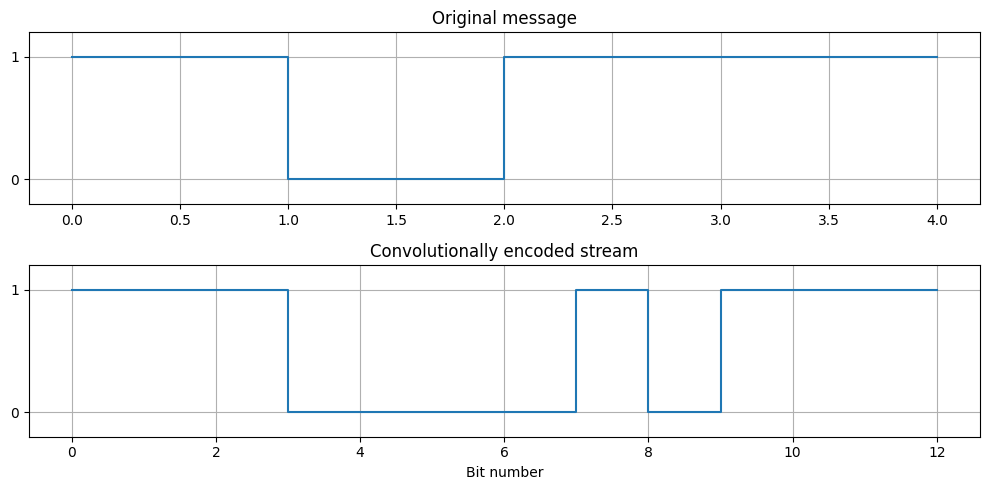

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].step(range(len(message)+1), message + [message[-1]], where='post')
ax[0].set_title('Original message')
ax[1].step(range(len(serial)+1), serial + [serial[-1]], where='post')
ax[1].set_title('Convolutionally encoded stream')
for a in ax: a.set_ylim(-0.2, 1.2); a.grid(True); a.set_yticks([0, 1])
ax[1].set_xlabel('Bit number')
fig.tight_layout();
plt.show()

## 4. Expected output and interpretation

- Printed **encoder input**: `[1, 0, 1, 1, 0, 0]`.
- Printed **output pairs**: `11 10 00 01 01 11`.
- Printed **encoded stream**: `111000010111`.
- Plot 1: the original four input bits; Plot 2: 12 serialized output bits.

**Result to write:** A $(2,1,2)$ convolutional encoder was implemented. For input `1011` followed by two termination zeros, it produced `11 10 00 01 01 11` using shift registers and XOR operations.

## 5. Viva — short answers

**Q1. What is convolutional coding?** Encoding each input using the current input bit and previous stored bits.  
**Q2. Code rate?** $k/n=1/2$, i.e., two output bits per one input bit.  
**Q3. What is memory order here?** $m=2$ flip-flops.  
**Q4. Constraint length?** $K=m+1=3$.  
**Q5. Why append two zeros?** To terminate/flush the encoder's two memory elements.  
**Q6. What is XOR?** Output `1` if an odd number of inputs are `1`.  
**Q7. What are the generators?** $g_1=111$, $g_2=101$ (binary tap patterns).  
**Q8. How many coded bits result?** Six processed inputs $\times$ two output bits = **12** encoded bits.  
**Q9. What decoder is commonly associated with convolutional codes?** Viterbi decoding; it is **not implemented** in the supplied manual's Exp 12.

**Practice:** Derive the first 3 output pairs from the XOR equations before running the cell.
